In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# Building Dataframe #


In [2]:
# reading csv files into dataframes
cat = pd.read_csv('SAMI_Input_Cat_Cluster/samiDR3InputCatClusters.csv')
print('Sample Size of SAMI Input Catalogue Dataset:', len(cat))
print(cat.columns)
    # "Mstar","dex","Logarithm of stellar mass","phys.mass"

kin = pd.read_csv('SAMI_Kinematics/samiDR3StelKin.csv')
print('Sample Size of SAMI Stellar Kinematics Dataset:', len(kin))
print(kin.columns)
    # "SIGMA_RE","km/s","Velocity dispersion from Re Sersic aperture spectra","phys.veloc.dispersion"

morph = pd.read_csv('SAMI_Visual_Morphology/samiDR3VisualMorphology.csv')
print('Sample Size of SAMI Visual Morphology Dataset:', len(morph))
print(morph.columns)
    # "TYPE","none","Morphological Type 

Sample Size of SAMI Input Catalogue Dataset: 1433
Index(['Unnamed: 0', 'catid', 'ra_obj', 'dec_obj', 'r_petro', 'r_auto',
       'z_spec', 'm_r', 'r_e', 'mu_within_1re', 'mu_1re', 'mu_2re', 'ellip',
       'pa', 'g_i', 'mstar', 'r_on_rtwo', 'v_on_sigma', 'is_mem', 'surv_sami',
       'bad_class'],
      dtype='str')
Sample Size of SAMI Stellar Kinematics Dataset: 3426
Index(['Unnamed: 0', 'cubeid', 'cubeidpub', 'cubename', 'catid', 'pa_stelkin',
       'pa_stelkin_err', 'sigma_re', 'sigma_re_err', 'sigma_3kpc_round',
       'sigma_3kpc_round_err', 'sigma_1_4_arcsecond',
       'sigma_1_4_arcsecond_err', 'sigma_2_arcsecond', 'sigma_2_arcsecond_err',
       'sigma_3_arcsecond', 'sigma_3_arcsecond_err', 'sigma_4_arcsecond',
       'sigma_4_arcsecond_err', 'aper_corr_flag', 'rmax_aper_corr',
       'lambdar_re', 'lambdar_re_err', 'lambdar_max', 'lambdar_max_err',
       'vsigma_re', 'vsigma_re_err', 'vsigma_max', 'vsigma_max_err',
       'mean_k51_re', 'mean_k51_re_err', 'sigma_re_mge', 's

In [3]:
mass = cat[['catid', 'mstar', 'bad_class']]
print('Sample Size of Mass Dataset:\n', mass.head(20))
vdisp = kin[['catid', 'sigma_re']]
print('Sample Size of Velocity Dispersion Dataset:\n', vdisp)
type = morph[['catid', 'type']]
print('Sample Size of Morphology Dataset:\n', type)

Sample Size of Mass Dataset:
          catid      mstar  bad_class
0   9011900001  11.587700          0
1   9011900002  10.157130          8
2   9011900003  10.205531          0
3   9011900005   9.887663          0
4   9011900006  10.841409          0
5   9011900007   9.530834          0
6   9011900008  10.474614          8
7   9011900009  10.533861          0
8   9011900011  10.014269          0
9   9011900012   9.969811          0
10  9011900013  10.376080          0
11  9011900014   9.794188          0
12  9011900017   9.575955          0
13  9011900019   9.553915          0
14  9011900020   9.501628          0
15  9011900024  11.460869          0
16  9011900025   9.805207          0
17  9011900026  10.112734          0
18  9011900027  10.948296          0
19  9011900030  11.178338          0
Sample Size of Velocity Dispersion Dataset:
            catid    sigma_re
0           6821         NaN
1           6837         NaN
2           7139  235.612810
3           7206  106.101770
4  

In [4]:
morphcat = pd.merge(morph, mass, on='catid', how='inner')
df = pd.merge(morphcat, vdisp, on='catid', how='inner')
print('Final Data Set', len(df))
print(df.head(20))

Final Data Set 962
    Unnamed: 0       catid  type      mstar  bad_class    sigma_re
0         2151  9008500001   0.0  11.733240          0         NaN
1         2152  9008500002   0.0  11.733201          0         NaN
2         2153  9008500004   1.5  10.639072          0         NaN
3         2154  9008500007   0.0  10.939993          0  265.057370
4         2154  9008500007   0.0  10.939993          0         NaN
5         2155  9008500018   0.5  10.028619          0  130.505040
6         2156  9008500020   0.0  10.894950          0  170.477860
7         2157  9008500022   0.5  10.140078          0   98.179590
8         2158  9008500024   0.5  10.753547          0  187.108870
9         2159  9008500034   1.0  10.199323          0  143.926180
10        2160  9008500042   0.0  10.522638          0  202.322860
11        2161  9008500043   3.0   9.631680          0   53.505527
12        2162  9008500059   0.0  10.612209          0  204.846340
13        2163  9008500062   2.0  10.627398

In [5]:
elliptical = df[df['type'] == 0.0] # choosing only elliptical galaxies
# key defines elliptical galaxies as having the type = 0
    # 0.5 is for galaxies between elliptical and lenticular stages

print('Number of Elliptical Galaxies:', len(elliptical))
print('Elliptical Galaxies:\n', elliptical.head(20))

# Columns are just misaligned, there are mstar and sigma_re values

Number of Elliptical Galaxies: 152
Elliptical Galaxies:
     Unnamed: 0       catid  type      mstar  bad_class    sigma_re
0         2151  9008500001   0.0  11.733240          0         NaN
1         2152  9008500002   0.0  11.733201          0         NaN
3         2154  9008500007   0.0  10.939993          0  265.057370
4         2154  9008500007   0.0  10.939993          0         NaN
6         2156  9008500020   0.0  10.894950          0  170.477860
10        2160  9008500042   0.0  10.522638          0  202.322860
12        2162  9008500059   0.0  10.612209          0  204.846340
14        2164  9008500064   0.0  10.014470          0  125.197975
16        2166  9008500068   0.0  10.189114          8   87.443590
20        2170  9008500077   0.0  10.764045          0  183.164600
27        2177  9008500096   0.0  10.905760          0  164.250000
34        2184  9008500114   0.0  11.131812          0         NaN
36        2186  9008500118   0.0  10.358594          0  122.640700
44   

# Cleaning Data #

In [6]:
df_clean_elliptical = elliptical.dropna(subset = ['mstar', 'sigma_re'])
good_elliptical = df_clean_elliptical[df_clean_elliptical['bad_class'] == 0]

print('Cleaned Data Set', len(df_clean_elliptical))
print('Good Elliptical Galaxies', len(good_elliptical))
print(good_elliptical.head(20))

Cleaned Data Set 107
Good Elliptical Galaxies 106
     Unnamed: 0       catid  type      mstar  bad_class    sigma_re
3          2154  9008500007   0.0  10.939993          0  265.057370
6          2156  9008500020   0.0  10.894950          0  170.477860
10         2160  9008500042   0.0  10.522638          0  202.322860
12         2162  9008500059   0.0  10.612209          0  204.846340
14         2164  9008500064   0.0  10.014470          0  125.197975
20         2170  9008500077   0.0  10.764045          0  183.164600
27         2177  9008500096   0.0  10.905760          0  164.250000
36         2186  9008500118   0.0  10.358594          0  122.640700
44         2194  9008500138   0.0  10.378108          0  114.042900
45         2195  9008500139   0.0  10.479002          0  131.962300
52         2202  9008500169   0.0  10.709361          0  173.848070
57         2207  9008500182   0.0  10.435489          0  166.522140
71         2221  9008500225   0.0  10.922438          0  232.15227

# Plotting Mass against Velocity Dispersion #

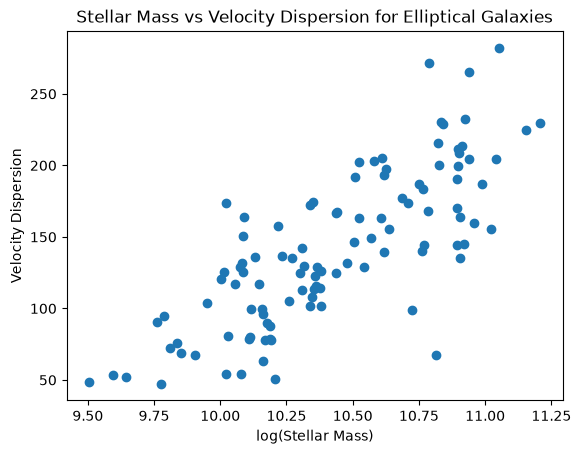

In [7]:
plt.scatter(df_clean_elliptical['mstar'], df_clean_elliptical['sigma_re'])
plt.title('Stellar Mass vs Velocity Dispersion for Elliptical Galaxies')
plt.xlabel('log(Stellar Mass)')
plt.ylabel('Velocity Dispersion')
plt.show()

In [ ]:
r = df_clean_elliptical['mstar'].corr(df_clean_elliptical['sigma_re'])
print("Correlation coefficient, r, between Stellar Mass and Velocity Dispersion for Elliptical Galaxies: ", r)


Correlation coefficient, r, between Stellar Mass and Velocity Dispersion for Elliptical Galaxies:  0.7768210578113118


In [ ]:
# stellar mass v dynamical mass

#dynamical mass = 5 * (sigma_re^2) * Re / G